In [3]:
%pip install pandas matplotlib scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------------------------- -------------- 5.2/8.4 MB 25.9 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 26.2 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ------ --------------------------------- 6.0/37.4 MB 30.6 MB/s eta 0:00:02
   ---------------- ----------------------- 15.5/37.4 MB 37.7 MB/s eta 0:00:01
   ------------------------- -------------- 23.9/37.4 MB 39.4 MB/s eta 0:00:01
   ----------------------------------- ---- 32.8/37.4 MB 39.5 MB/s eta 0:00:01
   -------------------------------------- - 35.7/37.4 MB 34.2 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 32.4 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 27.3 MB/s  0:00:01

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [6]:
# Load the breast cancer dataset
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

print("Dataset shape:", X.shape)
print("Target names:", cancer.target_names)

Dataset shape: (569, 30)
Target names: ['malignant' 'benign']


In [7]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (455, 30)
Testing data size: (114, 30)


In [8]:
# Scale the data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling done")

Feature scaling done


In [9]:
# Test different C values
C_values = [0.1, 1, 10, 100]

accuracy_list = []
time_list = []

for c in C_values:

    model = SVC(kernel='linear', C=c)

    start = time.time()
    model.fit(X_train, y_train)
    end = time.time()

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    accuracy_list.append(accuracy * 100)
    time_list.append(end - start)

    print("C value:", c)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Training time:", round(end - start, 4), "seconds")
    print("----------------------")

C value: 0.1
Accuracy: 98.25 %
Training time: 0.0049 seconds
----------------------
C value: 1
Accuracy: 97.37 %
Training time: 0.0054 seconds
----------------------
C value: 10
Accuracy: 98.25 %
Training time: 0.0082 seconds
----------------------
C value: 100
Accuracy: 97.37 %
Training time: 0.0195 seconds
----------------------


In [10]:
# Create a comparison table

comparison = pd.DataFrame({
    "C Value": C_values,
    "Accuracy (%)": accuracy_list,
    "Training Time (seconds)": time_list
})

comparison

,C Value,Accuracy (%),Training Time (seconds)
0,0.1,98.245614,0.004882
1,1.0,97.368421,0.005415
2,10.0,98.245614,0.008165
3,100.0,97.368421,0.019497


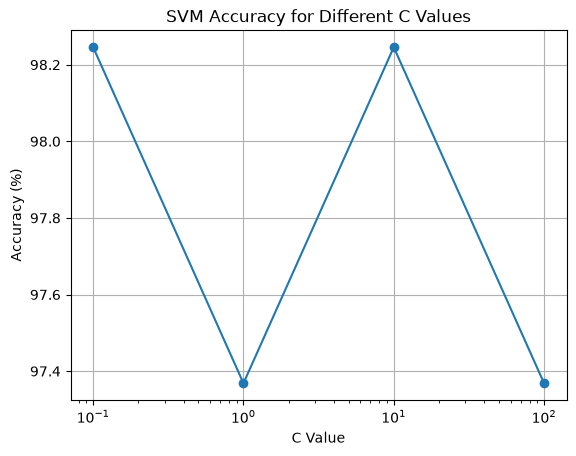

In [11]:
# Compare accuracy for different C values

plt.plot(C_values, accuracy_list, marker='o')

plt.xscale('log')
plt.xlabel("C Value")
plt.ylabel("Accuracy (%)")
plt.title("SVM Accuracy for Different C Values")
plt.grid(True)

plt.show()

### Conclusion

In this experiment, I tested the SVM model using four different C values: 0.1, 1, 10 and 100. I used the linear kernel and the same training and testing data for all models.

The results showed that C = 0.1 and C = 10 gave the highest accuracy of 98.25%. C = 1 and C = 100 gave 97.37% accuracy.

I also noticed that the training time increased when the C value became larger in my experiment. The model with C = 0.1 had the shortest training time, while C = 100 took the longest.

This experiment helped me understand that changing the C parameter can affect the accuracy and training time of an SVM model. A higher C value does not always give better accuracy. In my results, the smaller C values performed well, so a very high C was not necessary for this dataset.